# 01 · Preparar la base: catálogo de códigos de error Velora

**Este notebook se ejecuta una sola vez, antes de la clase.**

Velora es una marca de motos **inventada**. Su catálogo interno de códigos de error del tablero no existe en internet y ningún modelo lo conoce, así que es un caso natural para recuperar información antes de responder.

El catálogo tiene **120 códigos**, 24 por cada una de cinco categorías:

| Prefijo | Categoría |
|---|---|
| E | Motor e inyección |
| C | Sistema eléctrico |
| F | Frenos y suspensión |
| T | Transmisión y cadena |
| L | Refrigeración y lubricación |

Cada código tiene su **falla**, su **síntoma** y su **solución**.

Este notebook:

1. Crea en Supabase la tabla `codigos_velora`. **No toca** las tablas `memoria` ni `manual_velora`.
2. Guarda los 120 códigos con su embedding.
3. Valida los tres métodos de búsqueda (sparse, dense e hybrid) con 31 preguntas que no están en la base.

Los códigos de la moto eléctrica **E-Volt no se cargan aquí**. Se suben en vivo con el notebook `02_demo_codigos`.

In [14]:
# Colab ya trae numpy, pandas, scikit-learn y matplotlib.
%pip install -q "psycopg[binary]" pgvector umap-learn sentence-transformers

In [15]:
import os
import re
import time
import unicodedata
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from pgvector.psycopg import register_vector
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEMILLA = 42
MODELO = "intfloat/multilingual-e5-small"   # encoder de Hugging Face, no se reentrena
TABLA = "codigos_velora"                    # tabla de Supabase con el catálogo de códigos
K = 5                                       # códigos recuperados que votan por la categoría
NUEVA_CATEGORIA = "Moto eléctrica E-Volt"
np.random.seed(SEMILLA)

CATEGORIAS = ["Motor e inyección", "Sistema eléctrico", "Frenos y suspensión",
              "Transmisión y cadena", "Refrigeración y lubricación", NUEVA_CATEGORIA]
COLORES = dict(zip(CATEGORIAS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
MARCADORES = dict(zip(CATEGORIAS, ["o", "s", "^", "D", "v", "P"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# La cadena de conexión vive en los Secrets de Colab, nunca en el código
try:
    from google.colab import userdata
    DB_URL = userdata.get("SUPABASE_DB_URL")
except ImportError:
    DB_URL = os.environ["SUPABASE_DB_URL"]

modelo = SentenceTransformer(MODELO)
DIM = modelo.get_sentence_embedding_dimension()


def embeber(textos):
    # Convierte textos en vectores de norma 1 (los modelos e5 piden el prefijo "query: ").
    return modelo.encode(["query: " + t for t in textos], normalize_embeddings=True,
                         batch_size=32, show_progress_bar=False)


def armar_texto(codigo, categoria, falla, sintoma, solucion):
    # Texto completo de un código: es lo que se convierte en embedding y lo que lee BM25
    return f"Código {codigo}. Sistema: {categoria}. Falla: {falla}. Síntoma: {sintoma}. Solución: {solucion}"


print(f"Modelo cargado: {MODELO} ({DIM} dimensiones)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo cargado: intfloat/multilingual-e5-small (384 dimensiones)


## 1. El catálogo de códigos

In [16]:
#@title Catálogo de códigos Velora (ficticio, escrito para la demo)
CODIGOS = [
    ["E-01", "Motor e inyección", "Sensor de presión del múltiple (MAP) fuera de rango", "marcha mínima inestable y consumo alto de gasolina", "Revise la manguera de vacío y el conector del sensor MAP; reemplácelo si la lectura no cambia al acelerar."],
    ["E-02", "Motor e inyección", "Sensor de temperatura del aire de admisión con lectura errática", "arranque difícil cuando hace calor", "Limpie el conector y mida la resistencia del sensor de temperatura del aire."],
    ["E-03", "Motor e inyección", "Inyector de combustible obstruido", "la moto se apaga en ralentí y tironea al acelerar", "Limpie el inyector por ultrasonido; reemplácelo si el patrón de rociado es irregular."],
    ["E-04", "Motor e inyección", "Bobina de encendido sin señal", "el motor gira pero no hay chispa en la bujía", "Revise el capuchón de la bujía y mida la resistencia primaria de la bobina."],
    ["E-05", "Motor e inyección", "Bujía en corto o desgastada", "pérdida de potencia y fallas en las subidas", "Cambie la bujía y verifique la calibración de 0,8 mm."],
    ["E-06", "Motor e inyección", "Sensor de posición del cigüeñal sin señal", "el motor se apaga de repente andando y no vuelve a prender", "Revise la distancia del sensor al volante magnético y su cableado."],
    ["E-07", "Motor e inyección", "Sensor de posición del acelerador descalibrado", "la moto se queda acelerada sola", "Calibre el sensor de posición del acelerador con el escáner del taller."],
    ["E-08", "Motor e inyección", "Válvula de control de ralentí trabada", "el ralentí sube y baja solo", "Limpie el cuerpo de aceleración y la válvula de ralentí."],
    ["E-09", "Motor e inyección", "Bomba de gasolina sin presión", "el motor de arranque gira pero la moto no enciende", "Revise el fusible y el relé de la bomba y mida la presión de combustible."],
    ["E-10", "Motor e inyección", "Filtro de gasolina tapado", "la moto se apaga en subidas largas o a alta velocidad", "Cambie el filtro de gasolina."],
    ["E-11", "Motor e inyección", "Sensor de oxígeno sin señal", "humo negro y olor fuerte a gasolina", "Revise el conector del sensor en el exosto y reemplace el sensor."],
    ["E-12", "Motor e inyección", "Mezcla pobre detectada", "el motor petardea al desacelerar", "Busque entradas de aire falso en el múltiple y revise los empaques."],
    ["E-13", "Motor e inyección", "Mezcla rica detectada", "consumo de gasolina muy alto y bujía negra", "Revise el filtro de aire y la presión de combustible."],
    ["E-14", "Motor e inyección", "Sin comunicación con la ECU", "luz de motor encendida y el escáner no conecta", "Revise el conector y la masa de la ECU; si persiste, reprograme la ECU en el taller."],
    ["E-15", "Motor e inyección", "Compresión baja en el cilindro", "pierde fuerza y arranca con dificultad en frío", "Mida la compresión y revise anillos y válvulas."],
    ["E-16", "Motor e inyección", "Holgura de válvulas fuera de rango", "golpeteo metálico en la parte alta del motor", "Calibre las válvulas: admisión 0,10 mm y escape 0,15 mm."],
    ["E-17", "Motor e inyección", "Cadenilla de distribución estirada", "ruido de cadena dentro del motor en ralentí", "Revise el tensor y cambie la cadenilla de distribución."],
    ["E-18", "Motor e inyección", "Detonación detectada por el sensor de golpe", "el motor cascabelea al subir lomas", "Use gasolina de buena calidad y haga descarbonización."],
    ["E-19", "Motor e inyección", "Cuerpo de aceleración sucio", "la moto responde lento al acelerar", "Limpie el cuerpo de aceleración con limpiador especial."],
    ["E-20", "Motor e inyección", "Fuga en el múltiple de admisión", "silbido al acelerar y ralentí alto", "Cambie el empaque del múltiple de admisión."],
    ["E-21", "Motor e inyección", "Sensor de presión barométrica con falla", "pierde potencia en zonas altas de montaña", "Revise el sensor barométrico integrado en la ECU."],
    ["E-22", "Motor e inyección", "Válvula del canister bloqueada", "olor fuerte a gasolina con la moto parada", "Revise la manguera y la válvula del canister."],
    ["E-23", "Motor e inyección", "Sobrerrevolución del motor", "el motor corta al llegar al límite de revoluciones", "Es una protección normal; evite llevar el motor al corte de forma constante."],
    ["E-24", "Motor e inyección", "Falla del arranque en frío", "tironea y se apaga los primeros minutos en las mañanas frías", "Deje calentar el motor un minuto y revise el sensor de temperatura del motor."],
    ["C-01", "Sistema eléctrico", "Voltaje de batería bajo", "las luces se ven débiles y la moto no arranca", "Cargue la batería con cargador lento; cámbiela si no retiene la carga."],
    ["C-02", "Sistema eléctrico", "Sobrevoltaje en el sistema de carga", "se funden los bombillos con frecuencia", "Revise el regulador; el voltaje de carga debe estar entre 13,5 y 14,5 V."],
    ["C-03", "Sistema eléctrico", "Regulador rectificador defectuoso", "la batería se descarga aunque la moto se use a diario", "Mida el voltaje de carga en marcha y cambie el regulador."],
    ["C-04", "Sistema eléctrico", "Estator con bobinas quemadas", "la batería no carga y hay olor a quemado", "Mida la resistencia del estator y reemplácelo."],
    ["C-05", "Sistema eléctrico", "Motor de arranque no gira", "solo se escucha un clic al oprimir el botón de arranque", "Revise el relé de arranque y las escobillas del motor de arranque."],
    ["C-06", "Sistema eléctrico", "Relé de arranque pegado", "el motor de arranque sigue girando después de soltar el botón", "Cambie el relé de arranque."],
    ["C-07", "Sistema eléctrico", "Fusible principal fundido", "no prende nada en la moto", "Busque el cortocircuito antes de cambiar el fusible principal de 15 A."],
    ["C-08", "Sistema eléctrico", "Cortocircuito en el circuito de luces", "se apagan las luces y se funde el fusible", "Revise el cableado del faro delantero."],
    ["C-09", "Sistema eléctrico", "Bombillo de direccional fundido", "las direccionales parpadean muy rápido", "Cambie el bombillo o instale el relé para direccionales LED."],
    ["C-10", "Sistema eléctrico", "Falla del circuito del pito", "el pito no suena", "Revise el fusible de 10 A y limpie los contactos del botón."],
    ["C-11", "Sistema eléctrico", "El inmovilizador no reconoce la llave", "la moto no enciende con la llave", "Pruebe con la llave de repuesto y reprograme la llave principal en el taller."],
    ["C-12", "Sistema eléctrico", "Sensor de velocidad sin señal", "el velocímetro marca cero aunque la moto esté andando", "Limpie y revise el conector del sensor en la rueda trasera."],
    ["C-13", "Sistema eléctrico", "Sensor de caída activado", "el motor no enciende después de una caída o volcamiento", "Levante la moto, apague la llave, espere 10 segundos y vuelva a encender."],
    ["C-14", "Sistema eléctrico", "Sensor de la pata lateral con falla", "la moto se apaga al meter un cambio", "Revise el interruptor de la pata lateral."],
    ["C-15", "Sistema eléctrico", "Interruptor del clutch con falla", "no arranca aunque se apriete el clutch", "Revise el interruptor de la manigueta del clutch."],
    ["C-16", "Sistema eléctrico", "Tablero sin comunicación", "el tablero se apaga o muestra rayas", "Revise el conector del tablero y su masa."],
    ["C-17", "Sistema eléctrico", "Luz de freno siempre encendida", "la luz de stop no se apaga", "Ajuste el interruptor del freno trasero."],
    ["C-18", "Sistema eléctrico", "Luz de freno no enciende", "la luz de stop no prende al frenar", "Revise el bombillo y los interruptores de freno."],
    ["C-19", "Sistema eléctrico", "Masa del chasis floja", "fallas eléctricas intermitentes al pasar por huecos", "Limpie y apriete la conexión de masa principal."],
    ["C-20", "Sistema eléctrico", "Puerto USB sin corriente", "el puerto no carga el celular", "Revise el fusible del puerto USB."],
    ["C-21", "Sistema eléctrico", "Exploradoras sin señal", "las luces auxiliares no prenden", "Revise el relé y el interruptor de las exploradoras."],
    ["C-22", "Sistema eléctrico", "Alarma activada sin motivo", "la alarma suena sola", "Ajuste la sensibilidad del sensor de movimiento de la alarma."],
    ["C-23", "Sistema eléctrico", "Batería sulfatada", "la batería está hinchada o tiene polvo blanco en los bornes", "Limpie los bornes y reemplace la batería."],
    ["C-24", "Sistema eléctrico", "Consumo de corriente con la moto apagada", "la batería amanece descargada", "Mida el consumo en reposo y revise la alarma y los accesorios instalados."],
    ["F-01", "Frenos y suspensión", "Sensor ABS delantero sin señal", "se enciende la luz ABS en el tablero", "Limpie el sensor y el anillo dentado de la rueda delantera."],
    ["F-02", "Frenos y suspensión", "Sensor ABS trasero sin señal", "luz ABS encendida y la rueda trasera frena sin antibloqueo", "Limpie y revise el sensor de la rueda trasera."],
    ["F-03", "Frenos y suspensión", "Módulo ABS sin presión", "la manigueta vibra fuerte y la moto frena poco", "Haga un diagnóstico del módulo ABS en el taller."],
    ["F-04", "Frenos y suspensión", "Nivel bajo de líquido de frenos delantero", "la manigueta del freno se va hasta el fondo", "Revise pastillas y fugas, y complete con líquido DOT 4."],
    ["F-05", "Frenos y suspensión", "Nivel bajo de líquido de frenos trasero", "el pedal del freno se siente largo", "Revise el depósito trasero y busque fugas."],
    ["F-06", "Frenos y suspensión", "Aire en el sistema de frenos", "el freno se siente esponjoso o blandito", "Purgue el sistema de frenos."],
    ["F-07", "Frenos y suspensión", "Pastillas delanteras gastadas", "chillido metálico al frenar", "Cambie las pastillas delanteras."],
    ["F-08", "Frenos y suspensión", "Pastillas traseras gastadas", "ruido de raspado en la rueda trasera al frenar", "Cambie las pastillas traseras."],
    ["F-09", "Frenos y suspensión", "Disco delantero alabeado", "la moto vibra al frenar fuerte", "Mida el alabeo del disco y cámbielo si supera 0,3 mm."],
    ["F-10", "Frenos y suspensión", "Mordaza de freno pegada", "la rueda se calienta y frena sola", "Limpie y lubrique los pasadores de la mordaza."],
    ["F-11", "Frenos y suspensión", "Líquido de frenos contaminado", "el freno pierde fuerza en bajadas largas", "Cambie el líquido de frenos DOT 4."],
    ["F-12", "Frenos y suspensión", "Retenes de la suspensión delantera dañados", "la suspensión bota aceite por las barras", "Cambie los retenes y el aceite de la suspensión."],
    ["F-13", "Frenos y suspensión", "Suspensión delantera sin aceite", "la moto rebota mucho al frenar", "Cambie el aceite de la telescópica."],
    ["F-14", "Frenos y suspensión", "Amortiguador trasero vencido", "rebota en los huecos y se siente suelta atrás", "Cambie o recargue el amortiguador trasero."],
    ["F-15", "Frenos y suspensión", "Precarga trasera mal ajustada", "la moto se hunde cuando lleva parrillero", "Ajuste la precarga del resorte trasero."],
    ["F-16", "Frenos y suspensión", "Rodamientos de dirección flojos", "golpeteo en la dirección al frenar", "Ajuste o cambie los rodamientos de dirección."],
    ["F-17", "Frenos y suspensión", "Dirección dura", "cuesta girar el manubrio", "Lubrique o cambie los rodamientos de dirección."],
    ["F-18", "Frenos y suspensión", "Rodamiento de la rueda delantera desgastado", "zumbido que aumenta con la velocidad", "Cambie los rodamientos de la rueda delantera."],
    ["F-19", "Frenos y suspensión", "Llanta delantera con baja presión", "la dirección se siente pesada", "Infle la llanta delantera a 29 psi."],
    ["F-20", "Frenos y suspensión", "Llanta trasera con baja presión", "la moto se siente inestable en las curvas", "Infle la llanta trasera a 33 psi, o 36 psi con parrillero."],
    ["F-21", "Frenos y suspensión", "Desgaste irregular de la llanta", "la moto tira hacia un lado", "Revise la alineación de la rueda trasera y la presión."],
    ["F-22", "Frenos y suspensión", "Freno trasero de tambor desajustado", "el freno de atrás casi no frena", "Ajuste el tensor del freno de tambor."],
    ["F-23", "Frenos y suspensión", "Bujes del basculante gastados", "la parte trasera se mueve de lado a lado", "Cambie los bujes del basculante."],
    ["F-24", "Frenos y suspensión", "Sensor de presión de llantas sin señal", "aparece un aviso de llanta en el tablero", "Revise la batería del sensor de presión de la llanta."],
    ["T-01", "Transmisión y cadena", "Sensor de neutro con falla", "no prende la luz N y la moto no arranca en neutro", "Revise el sensor de neutro ubicado sobre la caja de cambios."],
    ["T-02", "Transmisión y cadena", "Indicador de marcha errático", "el número del cambio parpadea en el tablero", "Limpie el sensor de posición de cambios."],
    ["T-03", "Transmisión y cadena", "Cadena destensionada", "la cadena suena o golpea al acelerar", "Ajuste la holgura de la cadena a 25 - 35 mm."],
    ["T-04", "Transmisión y cadena", "Cadena demasiado tensa", "ruido en la transmisión y desgaste rápido del piñón", "Afloje la cadena hasta la holgura correcta."],
    ["T-05", "Transmisión y cadena", "Kit de arrastre gastado", "la cadena salta en los piñones", "Cambie cadena, piñón y corona al mismo tiempo."],
    ["T-06", "Transmisión y cadena", "Clutch patina", "el motor se acelera pero la moto no avanza en las subidas", "Cambie los discos del clutch."],
    ["T-07", "Transmisión y cadena", "Clutch pegado", "la moto se mueve aunque el clutch esté apretado", "Ajuste la guaya y revise el aceite del motor."],
    ["T-08", "Transmisión y cadena", "Guaya del clutch estirada o reventada", "la manigueta del clutch queda floja", "Cambie la guaya del clutch."],
    ["T-09", "Transmisión y cadena", "Cambios duros", "cuesta meter los cambios", "Ajuste el juego de la guaya y revise las horquillas."],
    ["T-10", "Transmisión y cadena", "La caja se sale de cambio", "la moto se sale de un cambio al acelerar", "Revise las horquillas y los engranajes de la caja."],
    ["T-11", "Transmisión y cadena", "Pedal de cambios flojo", "el pedal de cambios baila", "Apriete el tornillo del pedal de cambios."],
    ["T-12", "Transmisión y cadena", "Piñón de salida con juego", "golpe metálico al soltar el clutch", "Apriete la tuerca del piñón de salida."],
    ["T-13", "Transmisión y cadena", "Cauchos del porta corona gastados", "tirones al acelerar y al soltar el acelerador", "Cambie los cauchos del porta corona."],
    ["T-14", "Transmisión y cadena", "Rodamiento de la rueda trasera desgastado", "zumbido en la parte trasera de la moto", "Cambie los rodamientos de la rueda trasera."],
    ["T-15", "Transmisión y cadena", "Rueda trasera desalineada", "la cadena se corre hacia un lado", "Alinee la rueda con las marcas del basculante."],
    ["T-16", "Transmisión y cadena", "Guía de cadena desgastada", "la cadena roza el basculante", "Cambie el deslizador de la cadena."],
    ["T-17", "Transmisión y cadena", "Aceite de la caja contaminado", "los cambios suenan y raspan", "Cambie el aceite."],
    ["T-18", "Transmisión y cadena", "Bloqueo de arranque en cambio", "no arranca en cambio aunque se apriete el clutch", "Revise el sensor de la pata lateral y el interruptor del clutch."],
    ["T-19", "Transmisión y cadena", "Selector de cambios dañado", "la moto se queda en un solo cambio", "Revise el selector y su resorte."],
    ["T-20", "Transmisión y cadena", "Clutch sobrecalentado", "olor a quemado después de un trancón", "Deje enfriar y evite mantener el clutch a medias."],
    ["T-21", "Transmisión y cadena", "Cadena sin lubricación", "la cadena chilla y se ve oxidada", "Limpie y lubrique la cadena cada 500 km."],
    ["T-22", "Transmisión y cadena", "Piñón con dientes en punta", "la cadena hace ruido aun bien tensionada", "Cambie el kit de arrastre."],
    ["T-23", "Transmisión y cadena", "Tensor de cadena trabado", "no se puede ajustar la cadena", "Libere y lubrique el tensor de la cadena."],
    ["T-24", "Transmisión y cadena", "Rodamiento de la caja desgastado", "zumbido en neutro que desaparece al apretar el clutch", "Revise los rodamientos de la caja de cambios."],
    ["L-01", "Refrigeración y lubricación", "Temperatura del motor demasiado alta", "la aguja de temperatura está en rojo", "Detenga la moto, deje enfriar y revise el refrigerante."],
    ["L-02", "Refrigeración y lubricación", "Nivel de refrigerante bajo", "el depósito de refrigerante está bajo el mínimo", "Complete con refrigerante y busque fugas."],
    ["L-03", "Refrigeración y lubricación", "El ventilador no enciende", "la moto se recalienta en los trancones", "Revise el fusible y el relé del ventilador."],
    ["L-04", "Refrigeración y lubricación", "Ventilador siempre encendido", "el ventilador nunca se apaga", "Revise el sensor de temperatura del refrigerante."],
    ["L-05", "Refrigeración y lubricación", "Termostato pegado abierto", "el motor no llega a su temperatura normal en las mañanas", "Cambie el termostato."],
    ["L-06", "Refrigeración y lubricación", "Termostato pegado cerrado", "se recalienta rápido aunque tenga refrigerante", "Cambie el termostato."],
    ["L-07", "Refrigeración y lubricación", "Fuga en el radiador", "gotea líquido verde debajo de la moto", "Revise el radiador y las mangueras."],
    ["L-08", "Refrigeración y lubricación", "Tapa del radiador defectuosa", "el refrigerante se bota por el depósito", "Cambie la tapa del radiador."],
    ["L-09", "Refrigeración y lubricación", "Sello de la bomba de agua con fuga", "gotea refrigerante por el costado del motor", "Cambie el sello de la bomba de agua."],
    ["L-10", "Refrigeración y lubricación", "Radiador tapado de barro", "se recalienta después de rodar por destapado", "Lave el panal del radiador con agua a baja presión."],
    ["L-11", "Refrigeración y lubricación", "Presión de aceite baja", "la luz de aceite está encendida", "Apague el motor de inmediato y revise el nivel de aceite."],
    ["L-12", "Refrigeración y lubricación", "Nivel de aceite bajo", "el aceite no se ve en la mirilla", "Complete el aceite y busque fugas."],
    ["L-13", "Refrigeración y lubricación", "Aceite vencido", "el aceite está negro y espeso", "Cambie el aceite; el intervalo es de 3.000 km."],
    ["L-14", "Refrigeración y lubricación", "Consumo de aceite del motor", "sale humo azul por el exosto", "Mida la compresión y revise anillos y guías de válvula."],
    ["L-15", "Refrigeración y lubricación", "Fuga por el empaque de la tapa de válvulas", "hay aceite en la parte alta del motor", "Cambie el empaque de la tapa de válvulas."],
    ["L-16", "Refrigeración y lubricación", "Fuga por el tapón del cárter", "gotea aceite debajo del motor", "Cambie la arandela del tapón del cárter."],
    ["L-17", "Refrigeración y lubricación", "Filtro de aceite tapado", "presión de aceite baja a altas revoluciones", "Cambie el filtro de aceite."],
    ["L-18", "Refrigeración y lubricación", "Bomba de aceite desgastada", "la luz de aceite parpadea en ralentí con el motor caliente", "Revise la bomba de aceite."],
    ["L-19", "Refrigeración y lubricación", "Aceite contaminado con agua", "el aceite se ve como café con leche", "Revise el empaque de culata y la bomba de agua."],
    ["L-20", "Refrigeración y lubricación", "Aceite incorrecto", "el clutch empieza a patinar después de un cambio de aceite", "Use aceite para moto con norma JASO MA, nunca aceite de carro."],
    ["L-21", "Refrigeración y lubricación", "Exceso de aceite en el motor", "el nivel de aceite pasa la marca máxima", "Drene aceite hasta el nivel correcto."],
    ["L-22", "Refrigeración y lubricación", "Sensor de temperatura del aceite con falla", "la lectura de temperatura del aceite es errática", "Revise el sensor y su conector."],
    ["L-23", "Refrigeración y lubricación", "Enfriador de aceite tapado", "el aceite se calienta mucho en viajes largos", "Limpie el enfriador de aceite."],
    ["L-24", "Refrigeración y lubricación", "Mangueras de refrigerante resecas", "las mangueras del radiador están agrietadas", "Cambie las mangueras de refrigerante."],
]

PRUEBA = [
    ["Me aparece el código E-03 en el tablero", "E-03", "código"],
    ["¿Qué significa C-11?", "C-11", "código"],
    ["La moto marca F-06", "F-06", "código"],
    ["Salió T-05, ¿es grave?", "T-05", "código"],
    ["En la pantalla dice L-11", "L-11", "código"],
    ["¿Qué hago con un C-23?", "C-23", "código"],
    ["La Trail tiene el F-01", "F-01", "código"],
    ["Me sale T-17", "T-17", "código"],
    ["Código L-06 en el tablero", "L-06", "código"],
    ["¿Qué es el E-16?", "E-16", "código"],
    ["La moto se me apaga cuando paro en un semáforo", "E-03", "síntoma"],
    ["Se me cayó la moto y ahora no quiere prender", "C-13", "síntoma"],
    ["El velocímetro se quedó en cero aunque voy andando", "C-12", "síntoma"],
    ["Las direccionales titilan muy rápido", "C-09", "síntoma"],
    ["La batería amanece descargada todos los días", "C-24", "síntoma"],
    ["Cuando freno suena un chillido metálico", "F-07", "síntoma"],
    ["El freno de adelante se siente blandito", "F-06", "síntoma"],
    ["La moto vibra cuando freno duro", "F-09", "síntoma"],
    ["Suena la cadena cuando acelero", "T-03", "síntoma"],
    ["El clutch patina cuando subo una loma", "T-06", "síntoma"],
    ["Sale humo azulado por el exosto", "L-14", "síntoma"],
    ["El aceite se ve como café con leche", "L-19", "síntoma"],
    ["Se recalienta cuando estoy en un trancón", "L-03", "síntoma"],
    ["Huele mucho a gasolina con la moto parada", "E-22", "síntoma"],
    ["Se me hunde la moto cuando llevo parrillero", "F-15", "síntoma"],
    ["Pierde fuerza cuando subo a la montaña", "E-21", "síntoma"],
    ["Tengo el E-09 y el motor gira pero no prende", "E-09", "mixta"],
    ["Salió el L-01 y la aguja de temperatura está en rojo", "L-01", "mixta"],
    ["Me sale C-05 y solo suena un clic", "C-05", "mixta"],
    ["La moto marca T-01 y no prende la luz del neutro", "T-01", "mixta"],
    ["Apareció F-04 y la manigueta se va hasta el fondo", "F-04", "mixta"],
]

codigos_df = pd.DataFrame(CODIGOS, columns=["codigo", "categoria", "falla", "sintoma", "solucion"])
print(f"{len(codigos_df)} códigos y {len(PRUEBA)} preguntas de prueba")
codigos_df.groupby("categoria").size().rename("códigos").to_frame()

120 códigos y 31 preguntas de prueba


,códigos
categoria,
Frenos y suspensión,24
Motor e inyección,24
Refrigeración y lubricación,24
Sistema eléctrico,24
Transmisión y cadena,24


In [17]:
codigos_df.groupby("categoria").head(2)

,codigo,categoria,falla,sintoma,solucion
0,E-01,Motor e inyección,Sensor de presión del múltiple (MAP) fuera de rango,marcha mínima inestable y consumo alto de gasolina,Revise la manguera de vacío y el conector del sensor MAP; reemplácelo si la lectura no cambia al acelerar.
1,E-02,Motor e inyección,Sensor de temperatura del aire de admisión con lectura errática,arranque difícil cuando hace calor,Limpie el conector y mida la resistencia del sensor de temperatura del aire.
24,C-01,Sistema eléctrico,Voltaje de batería bajo,las luces se ven débiles y la moto no arranca,Cargue la batería con cargador lento; cámbiela si no retiene la carga.
25,C-02,Sistema eléctrico,Sobrevoltaje en el sistema de carga,se funden los bombillos con frecuencia,"Revise el regulador; el voltaje de carga debe estar entre 13,5 y 14,5 V."
48,F-01,Frenos y suspensión,Sensor ABS delantero sin señal,se enciende la luz ABS en el tablero,Limpie el sensor y el anillo dentado de la rueda delantera.
49,F-02,Frenos y suspensión,Sensor ABS trasero sin señal,luz ABS encendida y la rueda trasera frena sin antibloqueo,Limpie y revise el sensor de la rueda trasera.
72,T-01,Transmisión y cadena,Sensor de neutro con falla,no prende la luz N y la moto no arranca en neutro,Revise el sensor de neutro ubicado sobre la caja de cambios.
73,T-02,Transmisión y cadena,Indicador de marcha errático,el número del cambio parpadea en el tablero,Limpie el sensor de posición de cambios.
96,L-01,Refrigeración y lubricación,Temperatura del motor demasiado alta,la aguja de temperatura está en rojo,"Detenga la moto, deje enfriar y revise el refrigerante."
97,L-02,Refrigeración y lubricación,Nivel de refrigerante bajo,el depósito de refrigerante está bajo el mínimo,Complete con refrigerante y busque fugas.


In [18]:
# Así queda el texto de un código, que es lo que se guarda y se convierte en embedding
print(armar_texto(*CODIGOS[2]))

Código E-03. Sistema: Motor e inyección. Falla: Inyector de combustible obstruido. Síntoma: la moto se apaga en ralentí y tironea al acelerar. Solución: Limpie el inyector por ultrasonido; reemplácelo si el patrón de rociado es irregular.


## 2. Crear la tabla `codigos_velora` en Supabase

**Ojo:** esta celda borra `codigos_velora` si ya existía y la crea de nuevo vacía. Las otras tablas no se tocan.

In [19]:
conn = psycopg.connect(DB_URL, autocommit=True)
conn.execute("create extension if not exists vector")   # esto la vuelve una base de datos vectorial
register_vector(conn)
version = conn.execute("select extversion from pg_extension where extname = 'vector'").fetchone()[0]
print(f"Conectados a Supabase. pgvector activo, versión {version}")

Conectados a Supabase. pgvector activo, versión 0.8.2


In [20]:
conn.execute(f"drop table if exists {TABLA}")
conn.execute(f'''
    create table {TABLA} (
        id        bigserial primary key,
        codigo    text not null,
        categoria text not null,
        falla     text not null,
        sintoma   text not null,
        solucion  text not null,
        texto     text not null,
        embedding vector({DIM}) not null
    )
''')
conn.execute(f"create index {TABLA}_hnsw on {TABLA} using hnsw (embedding vector_cosine_ops)")
conn.execute(f"alter table {TABLA} enable row level security")   # que no quede expuesta en la API pública
print(f"Tabla `{TABLA}` creada con índice HNSW")

Tabla `codigos_velora` creada con índice HNSW


## 3. Calcular los embeddings y guardar los 120 códigos

In [21]:
def insertar_codigos(filas):
    # Guarda en Supabase una lista de (código, categoría, falla, síntoma, solución) con su embedding
    textos = [armar_texto(*f) for f in filas]
    vectores = embeber(textos)
    with conn.cursor() as cur:
        cur.executemany(
            f"insert into {TABLA} (codigo, categoria, falla, sintoma, solucion, texto, embedding) "
            "values (%s, %s, %s, %s, %s, %s, %s)",
            [(*f, t, v) for f, t, v in zip(filas, textos, vectores)])
    return len(filas)


t0 = time.perf_counter()
n = insertar_codigos(CODIGOS)
print(f"{n} códigos guardados en {time.perf_counter() - t0:.1f} s")
pd.DataFrame(conn.execute(f"select categoria, count(*) from {TABLA} group by categoria order by categoria").fetchall(),
             columns=["categoría", "códigos"])

120 códigos guardados en 17.8 s


,categoría,códigos
0,Frenos y suspensión,24
1,Motor e inyección,24
2,Refrigeración y lubricación,24
3,Sistema eléctrico,24
4,Transmisión y cadena,24


## 4. Validar: sparse, dense e hybrid

Cada pregunta de prueba tiene un código correcto. Medimos:

- **acierto@1**: el código correcto quedó en el primer lugar, que es la respuesta que se muestra;
- **acierto@3**: quedó entre los tres primeros;
- **MRR**: el promedio de 1 / posición del código correcto;
- **categoría correcta**: los 5 códigos recuperados votaron por la categoría correcta (k-NN).

Hay tres tipos de pregunta: solo con **código** ("me sale E-03"), solo con **síntoma** descrito con otras palabras ("se apaga en los semáforos") y **mixtas**.

In [22]:
# ---------- Sparse: BM25, búsqueda por palabras ----------
STOPWORDS = set("a al como con cual cuando de del el en es esta este hay la las le lo los me mi muy "
                "o para pero por que se si sin su un una y ya yo".split())
STOPWORDS |= set("codigo aparece aparecio sale salio marca dice tablero pantalla significa tiene tengo hago grave moto".split())

def tokens_bm25(texto):
    # Minúsculas, sin tildes, y los códigos como "E-03" se conservan como una sola palabra
    t = unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode()
    return [w for w in re.findall(r"[a-z]-\d+|[a-z0-9]+", t) if w not in STOPWORDS]


class BM25:
    def __init__(self, textos, k1=1.5, b=0.75):
        self.docs = [Counter(tokens_bm25(t)) for t in textos]
        self.largos = np.array([sum(d.values()) for d in self.docs])
        self.prom = self.largos.mean()
        self.k1, self.b, n = k1, b, len(textos)
        df = Counter(w for d in self.docs for w in d)
        self.idf = {w: np.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}

    def puntajes(self, consulta):
        q = tokens_bm25(consulta)
        s = np.zeros(len(self.docs))
        for i, (d, largo) in enumerate(zip(self.docs, self.largos)):
            for w in q:
                if w in d:
                    f = d[w]
                    s[i] += self.idf[w] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * largo / self.prom))
        return s


# ---------- El catálogo vive en Supabase ----------
COLUMNAS = ["id", "codigo", "categoria", "falla", "sintoma", "solucion", "texto"]


def cargar_catalogo():
    filas = conn.execute(f"select {', '.join(COLUMNAS)}, embedding from {TABLA} order by id").fetchall()
    tabla = pd.DataFrame([f[:-1] for f in filas], columns=COLUMNAS)
    E = np.vstack([np.asarray(f[-1].to_numpy() if hasattr(f[-1], "to_numpy") else f[-1], dtype=float) for f in filas])
    return tabla, E


def actualizar_indices():
    # Vuelve a leer el catálogo desde Supabase y reconstruye el índice BM25
    global catalogo, E_catalogo, bm25
    catalogo, E_catalogo = cargar_catalogo()
    bm25 = BM25(catalogo["texto"].tolist())


# ---------- Dense: embeddings con pgvector ----------
SQL_DENSE = f'''
    select id, 1 - (embedding <=> %(q)s) as similitud
    from {TABLA}
    order by embedding <=> %(q)s
    limit %(n)s
'''


def buscar(pregunta, metodo="hybrid", n=10, vector=None):
    # Devuelve los n códigos más relevantes según el método: sparse, dense o hybrid
    if metodo == "sparse":
        s = bm25.puntajes(pregunta)
        orden = np.argsort(-s)[:n]
        res = catalogo.iloc[orden].assign(puntaje=s[orden])
    elif metodo == "dense":
        v = embeber([pregunta])[0] if vector is None else vector
        filas = conn.execute(SQL_DENSE, {"q": v, "n": n}).fetchall()
        res = catalogo.set_index("id").loc[[f[0] for f in filas]].reset_index().assign(puntaje=[f[1] for f in filas])
    elif metodo == "hybrid":
        # Reciprocal Rank Fusion: suma 1 / (60 + posición) de cada código en las dos listas
        sparse = buscar(pregunta, "sparse", 20)
        sparse = sparse[sparse["puntaje"] > 0]          # solo códigos que comparten alguna palabra
        rrf = {}
        for lista in (sparse, buscar(pregunta, "dense", 20, vector)):
            for pos, i in enumerate(lista["id"], start=1):
                rrf[i] = rrf.get(i, 0) + 1 / (60 + pos)
        ids = sorted(rrf, key=rrf.get, reverse=True)[:n]
        res = catalogo.set_index("id").loc[ids].reset_index().assign(puntaje=[rrf[i] for i in ids])
    else:
        raise ValueError("metodo debe ser 'sparse', 'dense' o 'hybrid'")
    return res.reset_index(drop=True)


def categoria_votada(resultados, k=K):
    # k-NN: los k códigos recuperados votan por su categoría (empate: gana la del primero)
    top = list(resultados.head(k)["categoria"])
    return max(top, key=lambda c: (top.count(c), -top.index(c)))


def evaluar(metodo, preguntas):
    # Para cada pregunta de prueba: ¿en qué posición quedó el código correcto?
    filas = []
    for texto, codigo, tipo in preguntas:
        res = buscar(texto, metodo, n=10)
        codigos = list(res["codigo"])
        rango = codigos.index(codigo) + 1 if codigo in codigos else None
        filas.append({"pregunta": texto, "tipo": tipo, "correcto": codigo, "recuperado": codigos[0],
                      "acierto@1": rango == 1, "acierto@3": rango is not None and rango <= 3,
                      "MRR": 1 / rango if rango else 0.0,
                      "categoría correcta": categoria_votada(res) == CATEGORIA_DE[codigo]})
    return pd.DataFrame(filas)


def consultar(sql, params=None):
    cur = conn.execute(sql, params)
    return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])


actualizar_indices()
CATEGORIA_DE = dict(zip(catalogo["codigo"], catalogo["categoria"]))
print("Funciones de búsqueda listas")

Funciones de búsqueda listas


In [23]:
resultados = {m: evaluar(m, PRUEBA) for m in ["sparse", "dense", "hybrid"]}
resumen = pd.DataFrame({m: r[["acierto@1", "acierto@3", "MRR", "categoría correcta"]].mean()
                        for m, r in resultados.items()}).T
resumen.round(3)

,acierto@1,acierto@3,MRR,categoría correcta
sparse,0.871,0.903,0.899,0.548
dense,0.871,1.000,0.930,0.839
hybrid,0.871,0.968,0.924,0.903


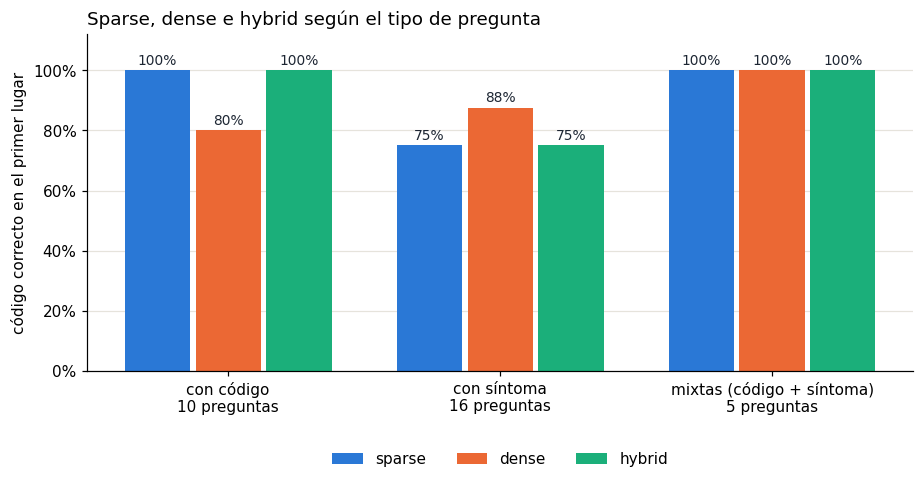

In [24]:
por_tipo = pd.DataFrame({m: r.groupby("tipo")["acierto@1"].mean() for m, r in resultados.items()}).T
por_tipo = por_tipo[[c for c in ["código", "síntoma", "mixta"] if c in por_tipo.columns]]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ancho = 0.26
colores_metodo = {"sparse": "#2a78d6", "dense": "#eb6834", "hybrid": "#1baf7a"}
x = np.arange(len(por_tipo.columns))
for j, metodo in enumerate(por_tipo.index):
    valores = por_tipo.loc[metodo].to_numpy()
    barras = ax.bar(x + (j - 1) * ancho, valores, width=ancho - 0.02, color=colores_metodo[metodo], label=metodo)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=9, color="#1d2633")
n_por_tipo = resultados["dense"]["tipo"].value_counts()
nombres = {"código": "con código", "síntoma": "con síntoma", "mixta": "mixtas (código + síntoma)"}
ax.set_xticks(x, [f"{nombres[t]}\n{n_por_tipo[t]} preguntas" for t in por_tipo.columns])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("código correcto en el primer lugar")
ax.set_title("Sparse, dense e hybrid según el tipo de pregunta", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="y", color="#e6e3dc", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [25]:
# Preguntas en las que al menos un método falló
detalle = resultados["dense"][["pregunta", "tipo", "correcto"]].copy()
for m, r in resultados.items():
    detalle[m] = r["recuperado"]
fallos = detalle[detalle[["sparse", "dense", "hybrid"]].ne(detalle["correcto"], axis=0).any(axis=1)]
print(f"Preguntas con al menos un fallo: {len(fallos)} de {len(detalle)}")
fallos

Preguntas con al menos un fallo: 7 de 31


,pregunta,tipo,correcto,sparse,dense,hybrid
2,La moto marca F-06,código,F-06,F-06,F-09,F-06
8,Código L-06 en el tablero,código,L-06,L-06,C-16,L-06
10,La moto se me apaga cuando paro en un semáforo,síntoma,E-03,C-16,C-13,C-14
11,Se me cayó la moto y ahora no quiere prender,síntoma,C-13,E-06,C-13,C-11
17,La moto vibra cuando freno duro,síntoma,F-09,F-22,F-09,F-03
22,Se recalienta cuando estoy en un trancón,síntoma,L-03,T-20,L-03,T-20
25,Pierde fuerza cuando subo a la montaña,síntoma,E-21,E-21,F-20,E-21


In [26]:
conn.close()
print("Listo. `codigos_velora` quedó con 120 códigos. La E-Volt se sube en clase con el notebook 02.")

Listo. `codigos_velora` quedó con 120 códigos. La E-Volt se sube en clase con el notebook 02.
